In [1]:
#Let's start with importing necessary libraries


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model  import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score

In [4]:
## read the dataset

In [5]:
data=pd.read_csv(r"C:\Users\Admin\OneDrive\Desktop\bank-additional-full.csv",sep=';',na_values='unknown')
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [6]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
data.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [8]:
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [9]:
data.describe(include='O')

C:\Users\Admin\AppData\Local\Temp\ipykernel_15328\849539315.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include='O')


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,40858,41108,39457,32591,40198,40198,41188,41188,41188,41188,41188
unique,11,3,7,2,2,2,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             40858 non-null  str    
 2   marital         41108 non-null  str    
 3   education       39457 non-null  str    
 4   default         32591 non-null  str    
 5   housing         40198 non-null  str    
 6   loan            40198 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

# Exploratory Data Analysis:-

## univariate Analysis

In [11]:
data.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [12]:
## Renaming certain columns just to make analysis easy

In [13]:
data.rename(columns={'emp.var.rate':'emp_var_rate','cons.price.idx':'cons_price_idx',
                     'cons.conf.idx':'cons_conf_idx',
                     'nr.employed':'nr_employed'}
            ,inplace=True)

In [14]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [15]:
import sweetviz as sv
my_report = sv.analyze(data)## pass the original dataframe
my_report.show_html() # Default arguments will generate to "SWEETVIZ_REPORT.html"

                                             |          | [  0%]   00:00 -> (? left)

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight nor

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


# Bivariate or Multivariate Analysis

In [16]:
data1=data[['age','duration','campaign','pdays','previous','emp_var_rate',
           'cons_price_idx','cons_conf_idx','euribor3m','nr_employed']]
data1

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...
41183,73,334,1,999,0,-1.1,94.767,-50.8,1.028,4963.6
41184,46,383,1,999,0,-1.1,94.767,-50.8,1.028,4963.6
41185,56,189,2,999,0,-1.1,94.767,-50.8,1.028,4963.6
41186,44,442,1,999,0,-1.1,94.767,-50.8,1.028,4963.6


findfont: Failed to find font weight normal, now using 500.


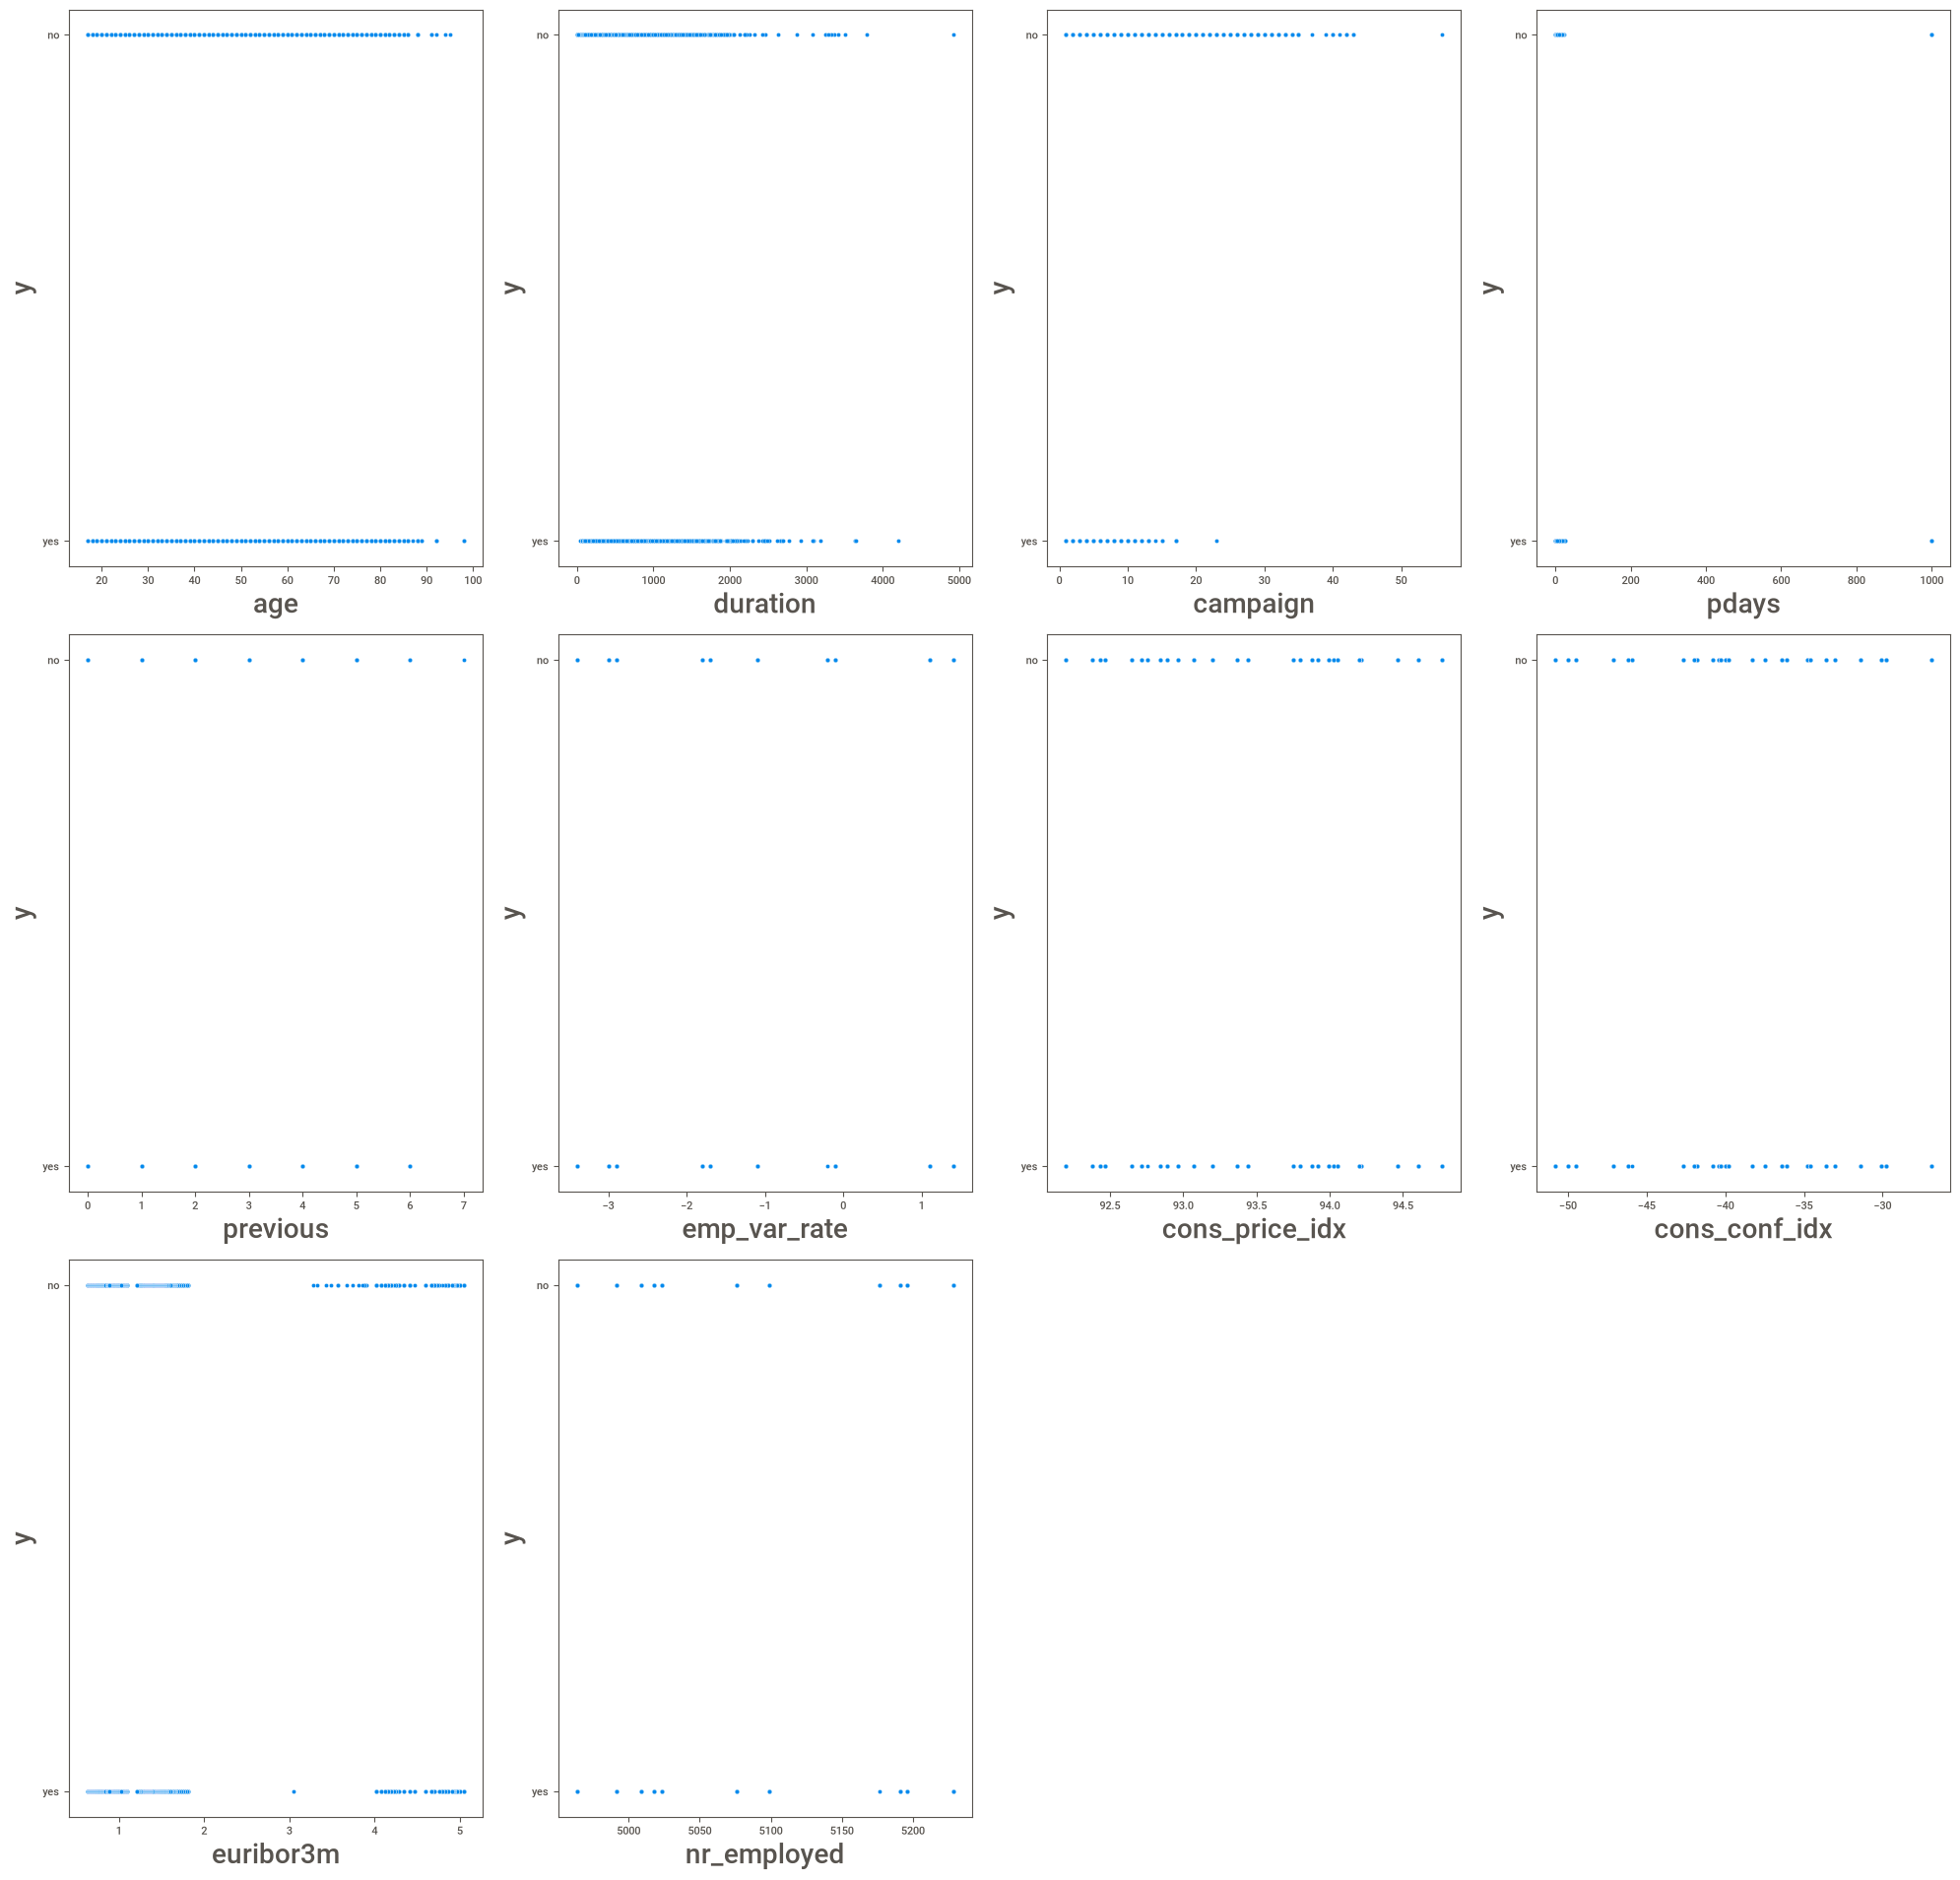

In [17]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber = 1

for column in data1:
    if plotnumber<=10 :   ## as there is 10 columns
        ax = plt.subplot(4,4,plotnumber)
        sns.scatterplot(x=data1[column].dropna(axis=0)
                        ,y=data.y)
        plt.xlabel(column,fontsize=20)
        plt.ylabel('y',fontsize=20)
    plotnumber+=1
plt.tight_layout()

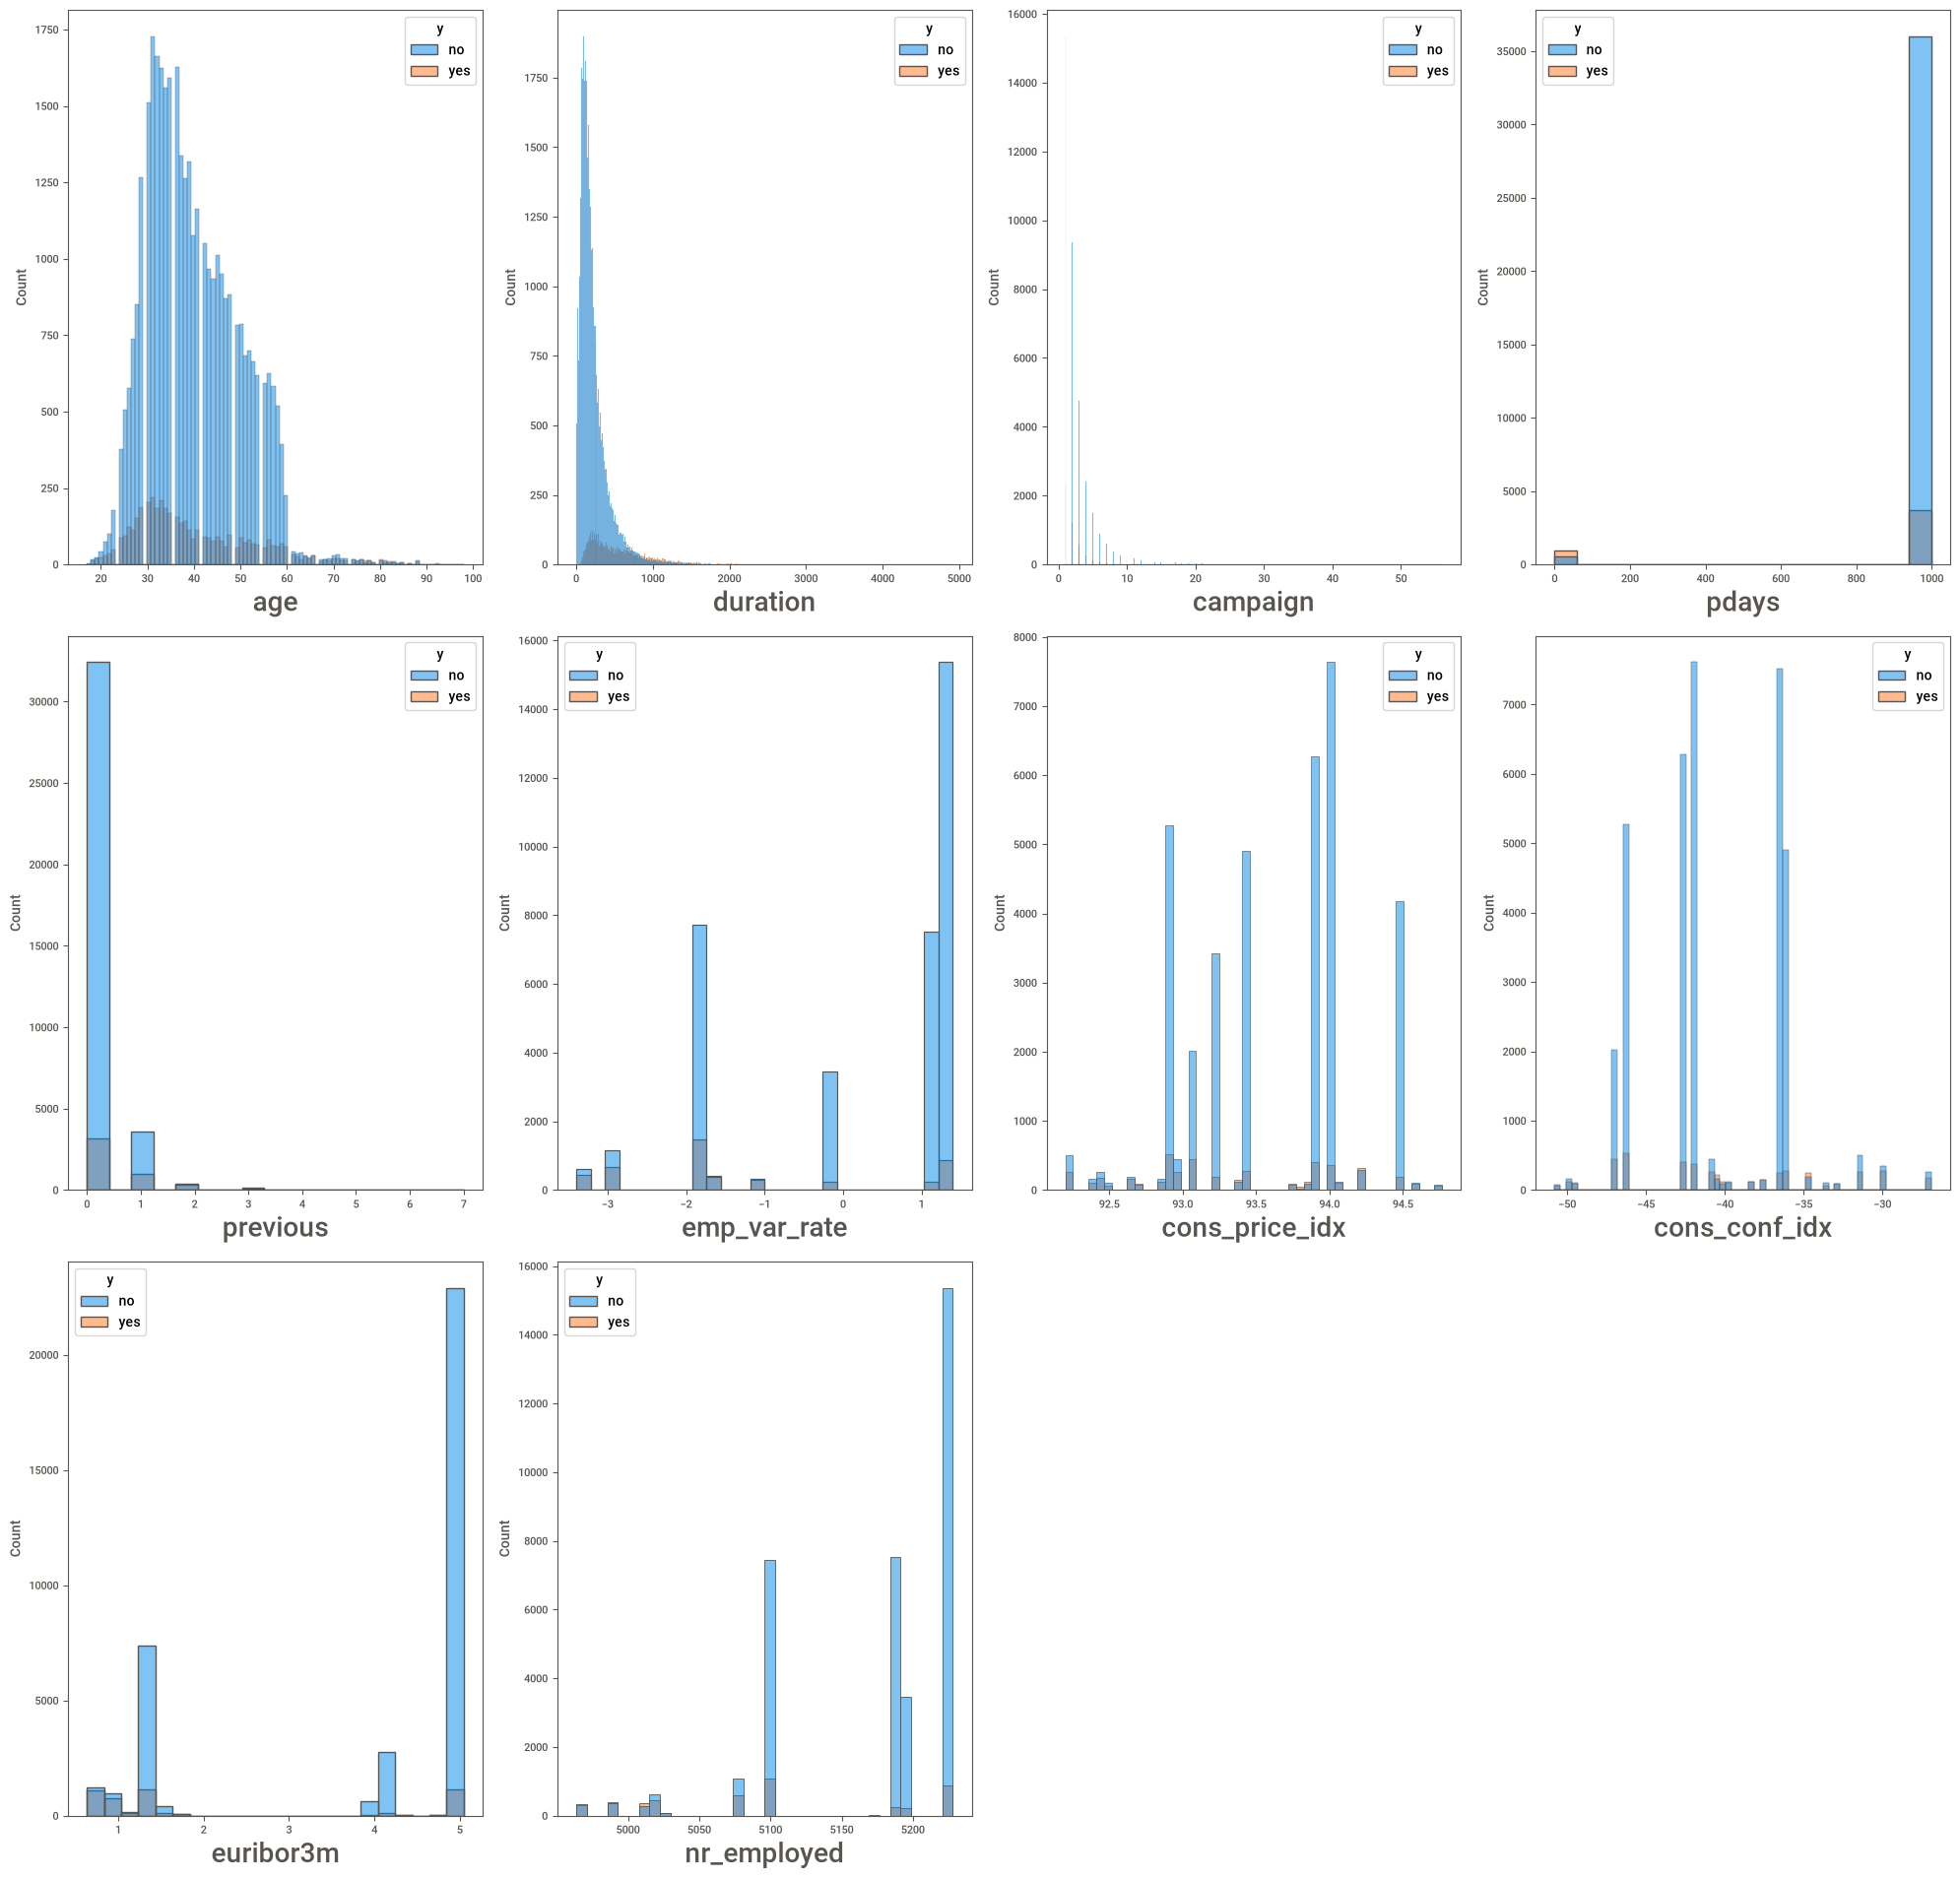

In [18]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax = plt.subplot(4,4,plotnumber)
        sns.histplot(x=data1[column],hue=data.y)
        plt.xlabel(column,fontsize=20)
    plotnumber+=1
plt.tight_layout()

C:\Users\Admin\AppData\Local\Temp\ipykernel_15328\936780587.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x=data1[column].dropna(axis=0))
C:\Users\Admin\AppData\Local\Temp\ipykernel_15328\936780587.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x=data1[column].dropna(axis=0))
C:\Users

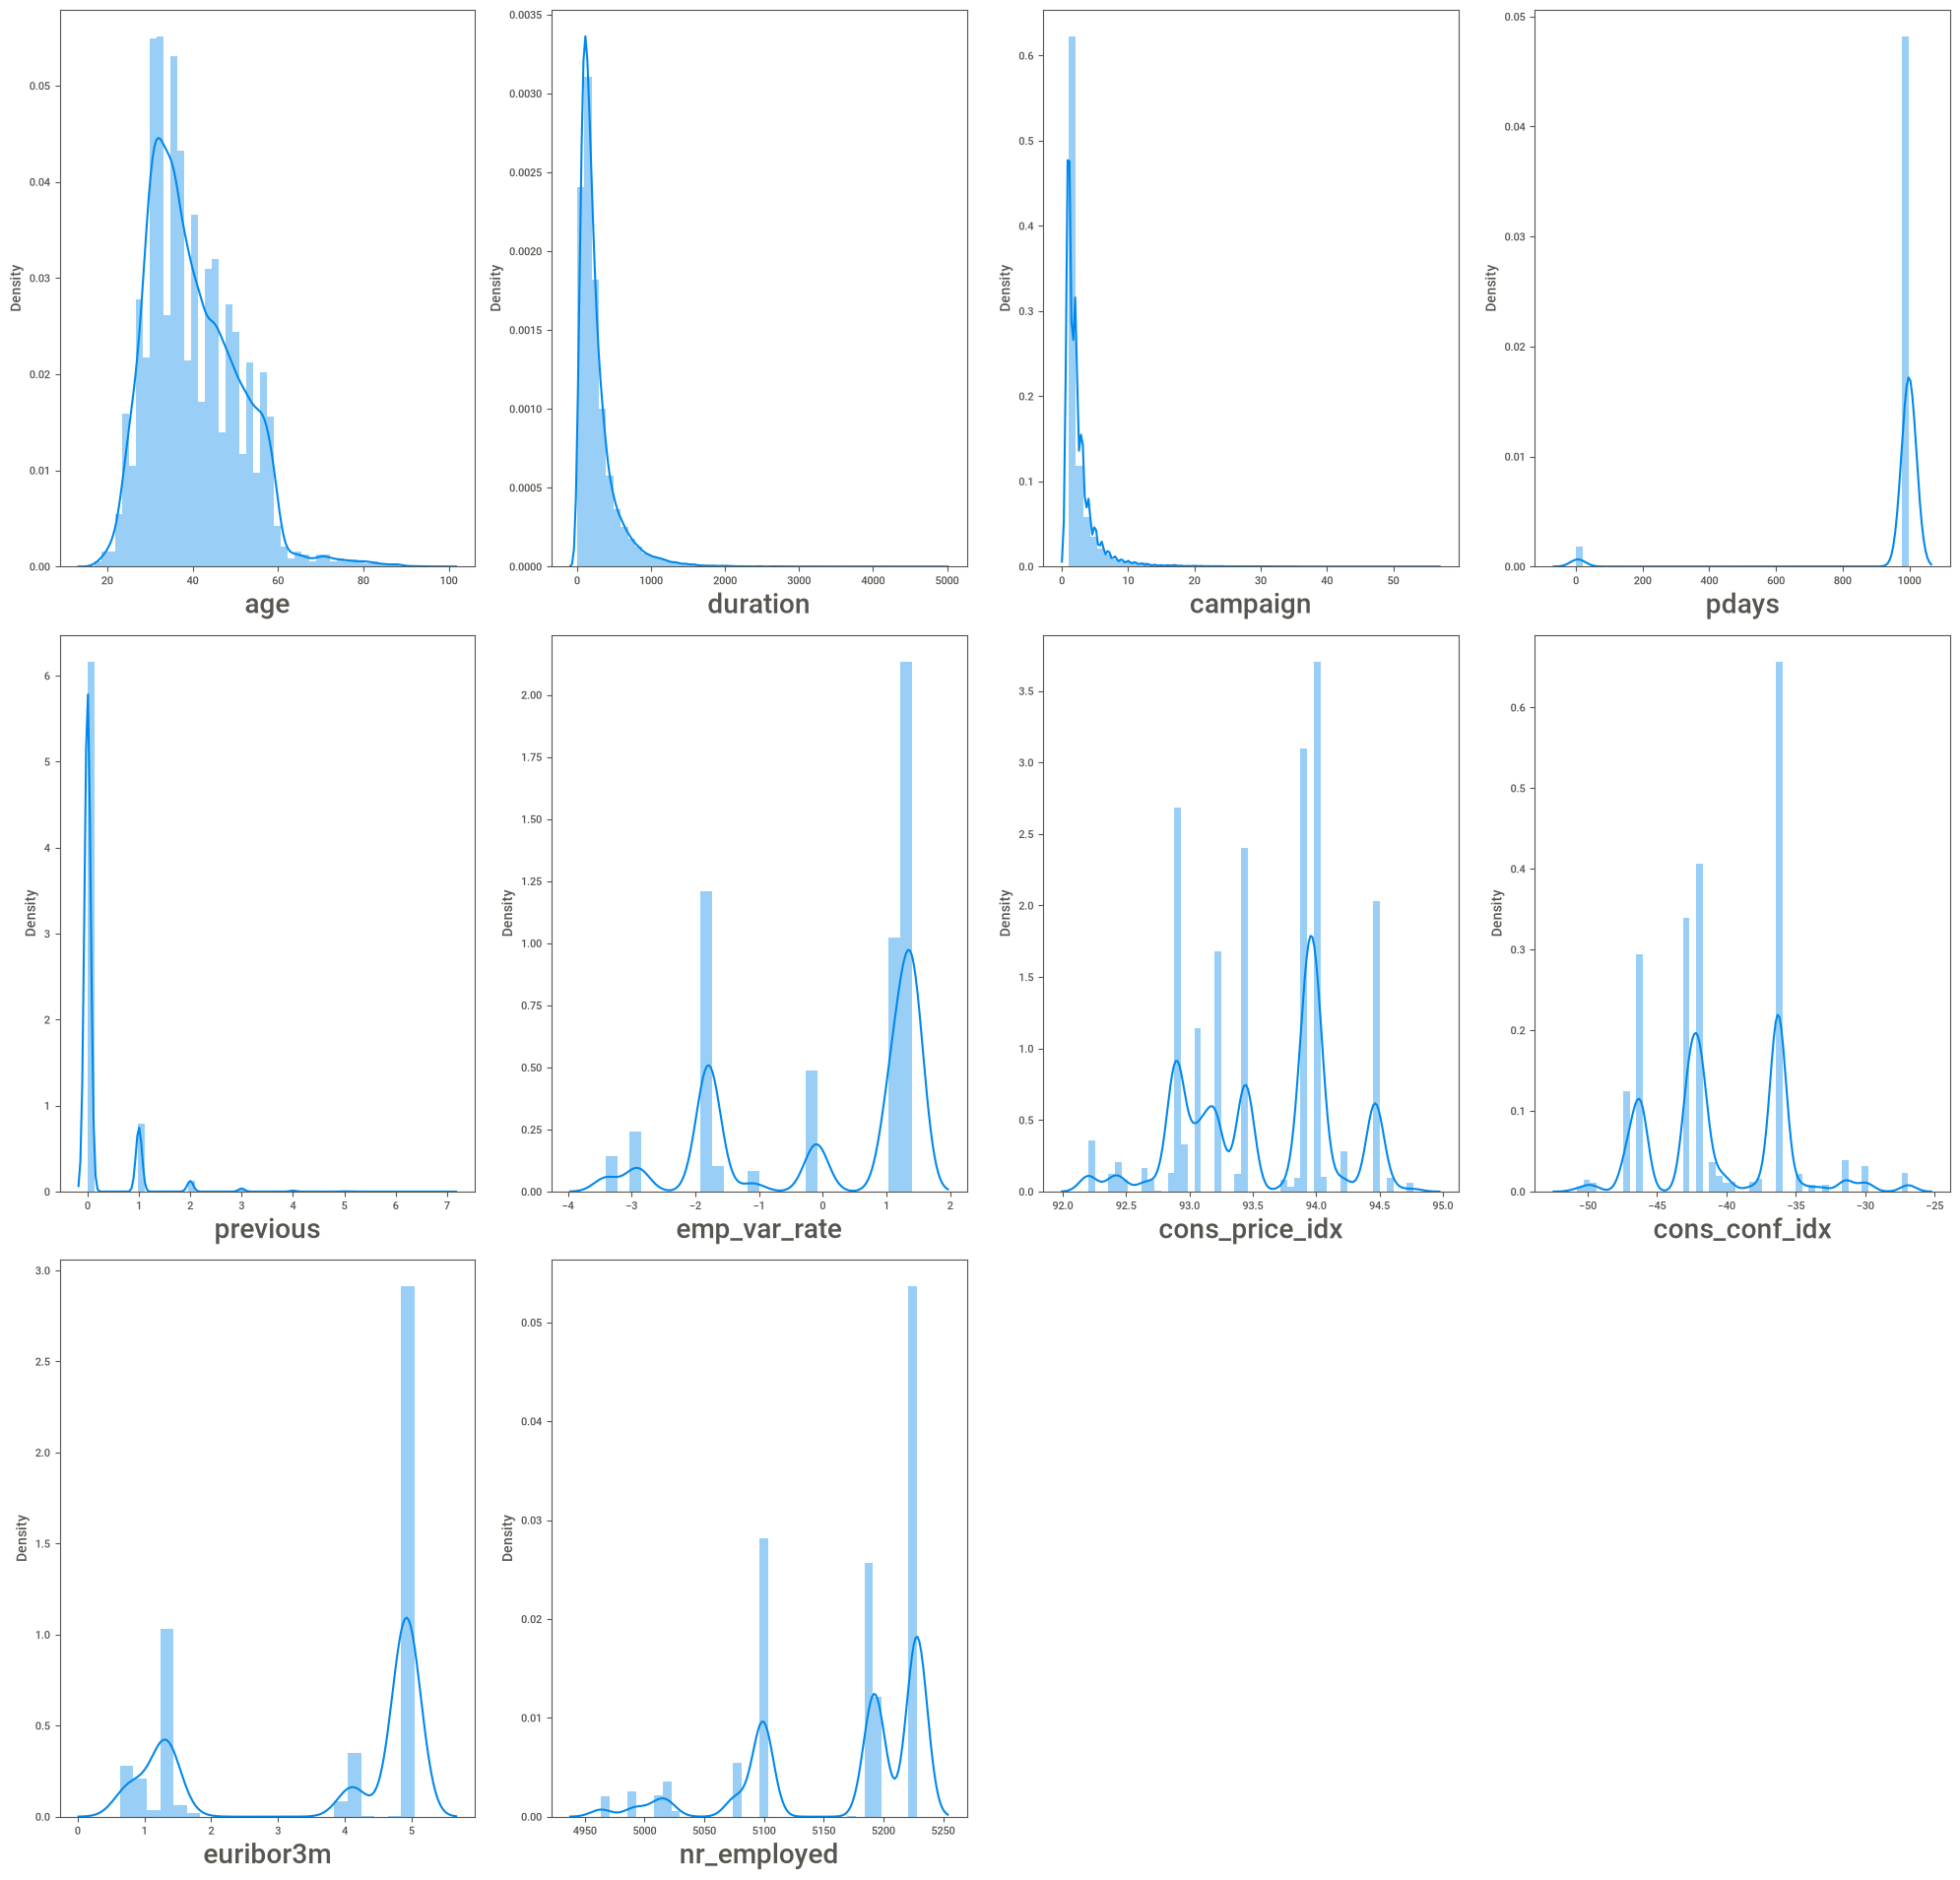

In [19]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax = plt.subplot(4,4,plotnumber)
        
        sns.distplot(x=data1[column].dropna(axis=0))
        plt.xlabel(column,fontsize=20)
        
    plotnumber+=1
plt.tight_layout()

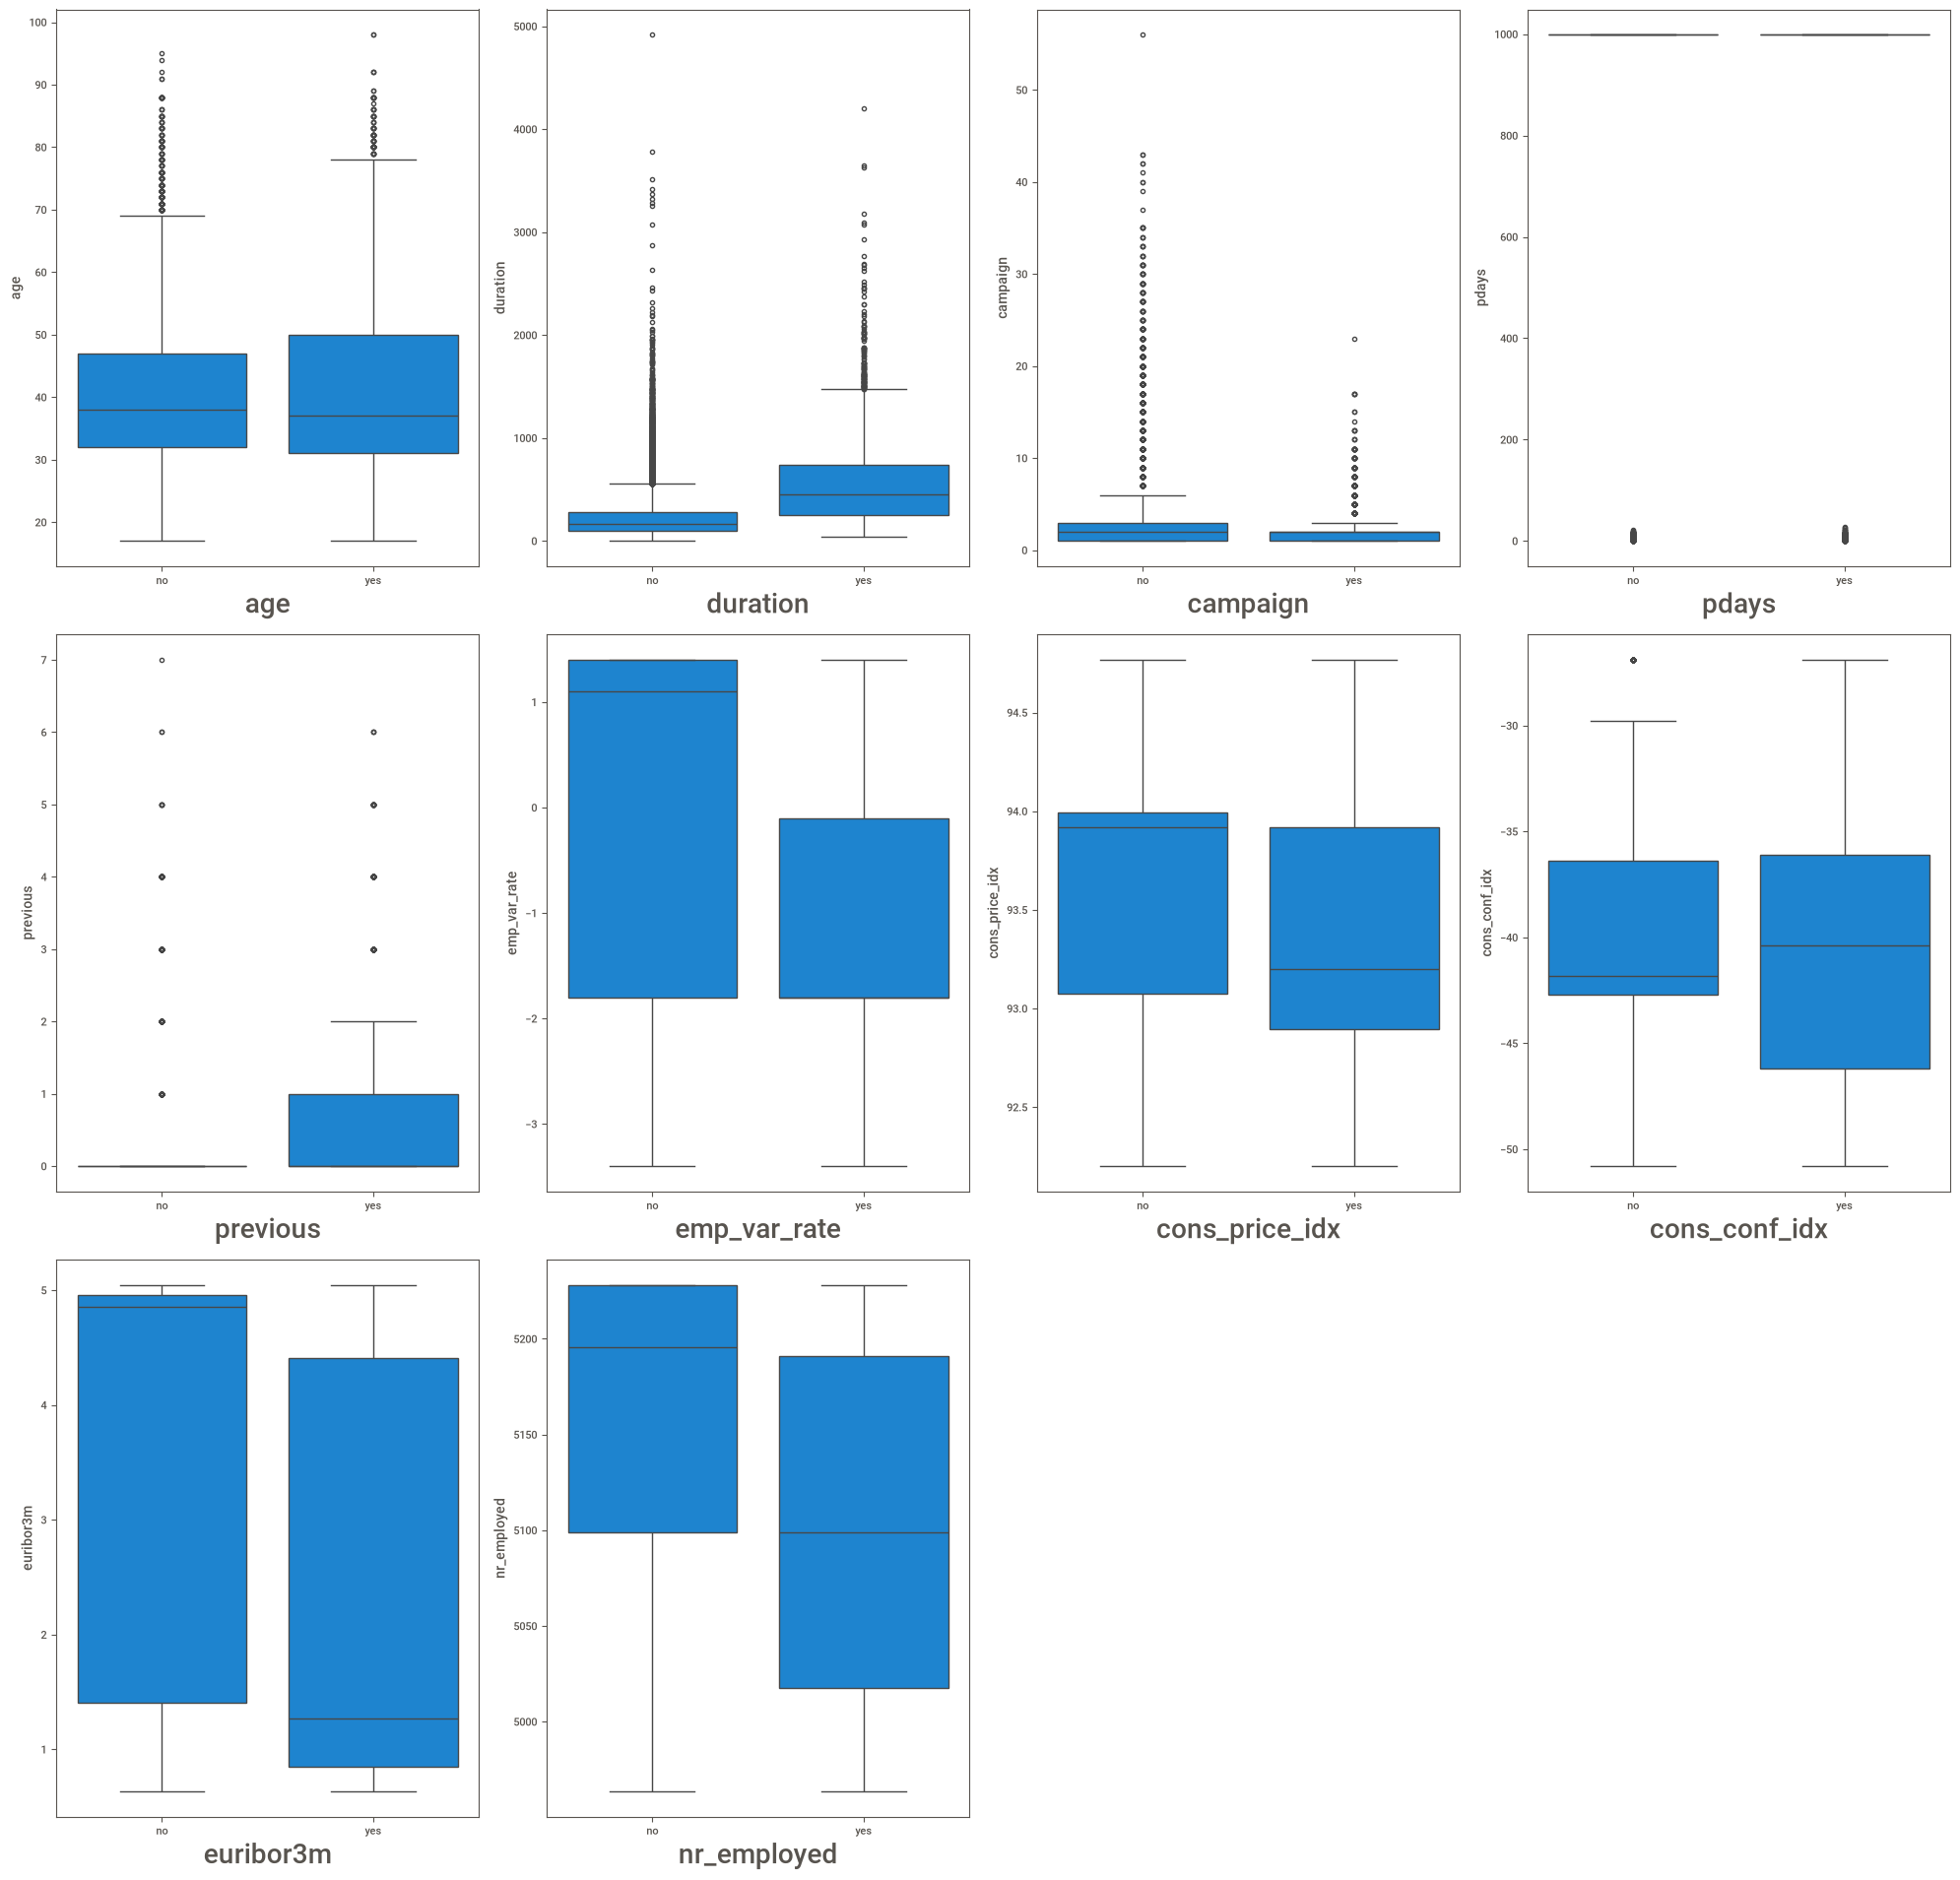

In [20]:
plt.figure(figsize=(20,25), facecolor='white')
plotnumber = 1

for column in data1:
    if plotnumber<=10 :
        ax = plt.subplot(4,4,plotnumber)
        sns.boxplot(x=data.y,y=data1[column])
        plt.xlabel(column,fontsize=20)
        
    plotnumber+=1
plt.tight_layout()

In [21]:
data.cons_conf_idx.value_counts()

cons_conf_idx
-36.4    7763
-42.7    6685
-46.2    5794
-36.1    5175
-41.8    4374
-42.0    3616
-47.1    2458
-31.4     770
-40.8     715
-26.9     447
-30.1     357
-40.3     311
-37.5     303
-50.0     282
-29.8     267
-34.8     264
-38.3     233
-39.8     229
-40.0     212
-49.5     204
-33.6     178
-34.6     174
-33.0     172
-50.8     128
-40.4      67
-45.9      10
Name: count, dtype: int64

In [22]:
# Build a function to show categorical values disribution

In [23]:
def plot_bar(column):
    # temp df 
    temp_1 = pd.DataFrame()
    # count categorical values
    temp_1['No_deposit'] = data[data['y'] == 'no'][column].value_counts()
    temp_1['Yes_deposit'] = data[data['y'] == 'yes'][column].value_counts()
    temp_1.plot(kind='bar')
    plt.xlabel(f'{column}')
    plt.ylabel('Number of clients')
    plt.title('Distribution of {} and deposit'.format(column))
    plt.show()

findfont: Failed to find font weight normal, now using 500.


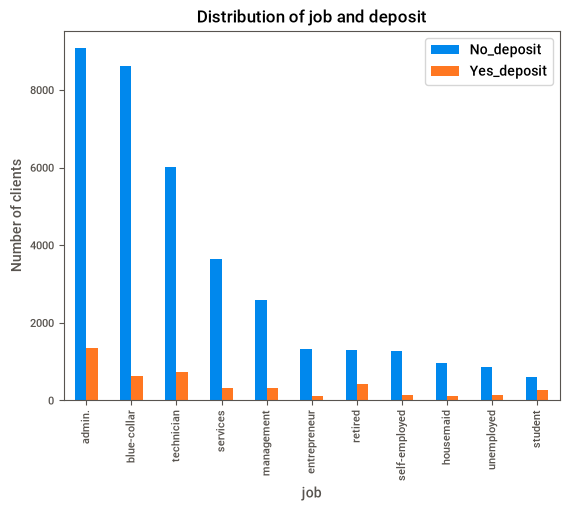

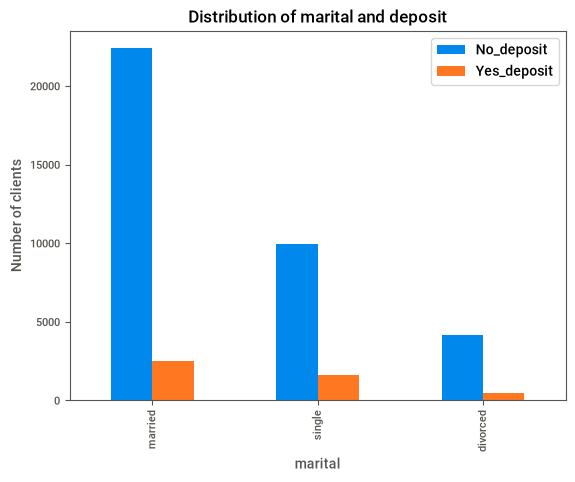

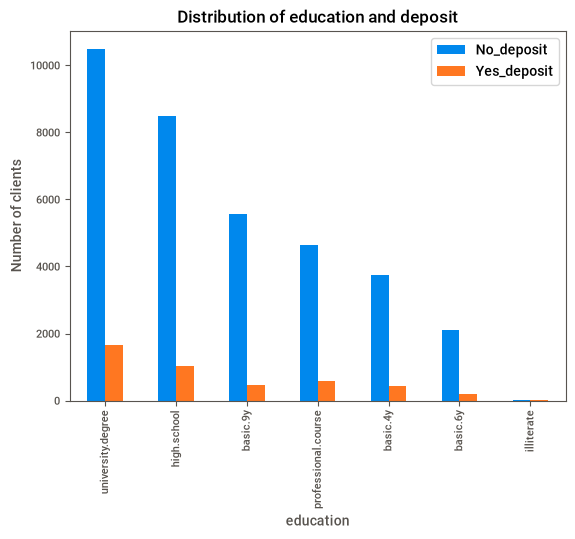

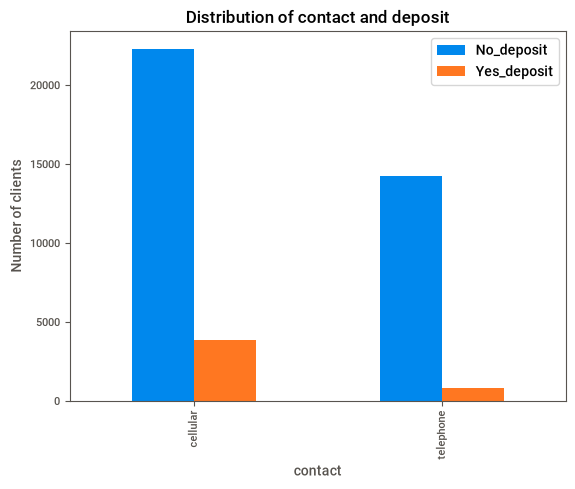

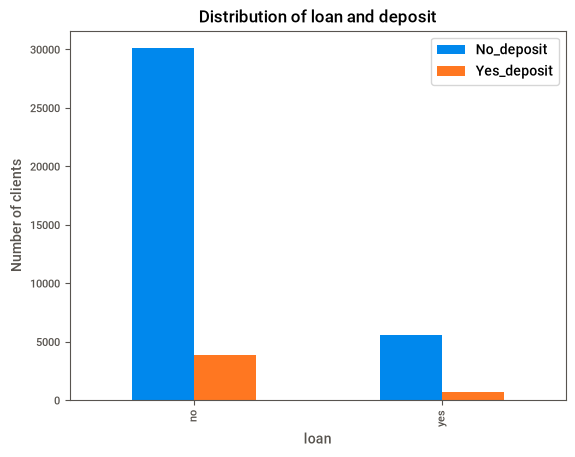

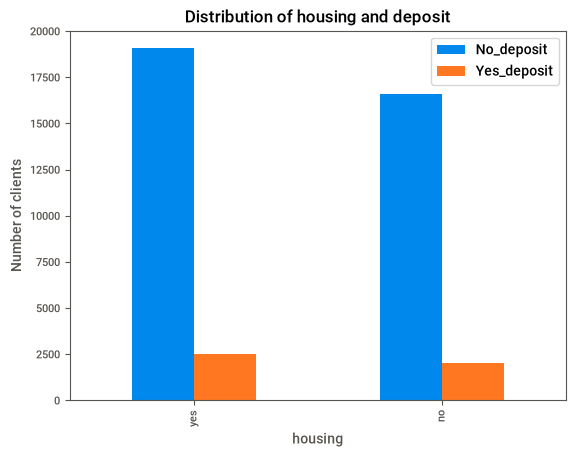

(None, None, None, None, None, None)

In [24]:
plot_bar('job'), plot_bar('marital'), plot_bar('education'), plot_bar('contact'), plot_bar('loan'), plot_bar('housing')

# Categorical Feature Distributions

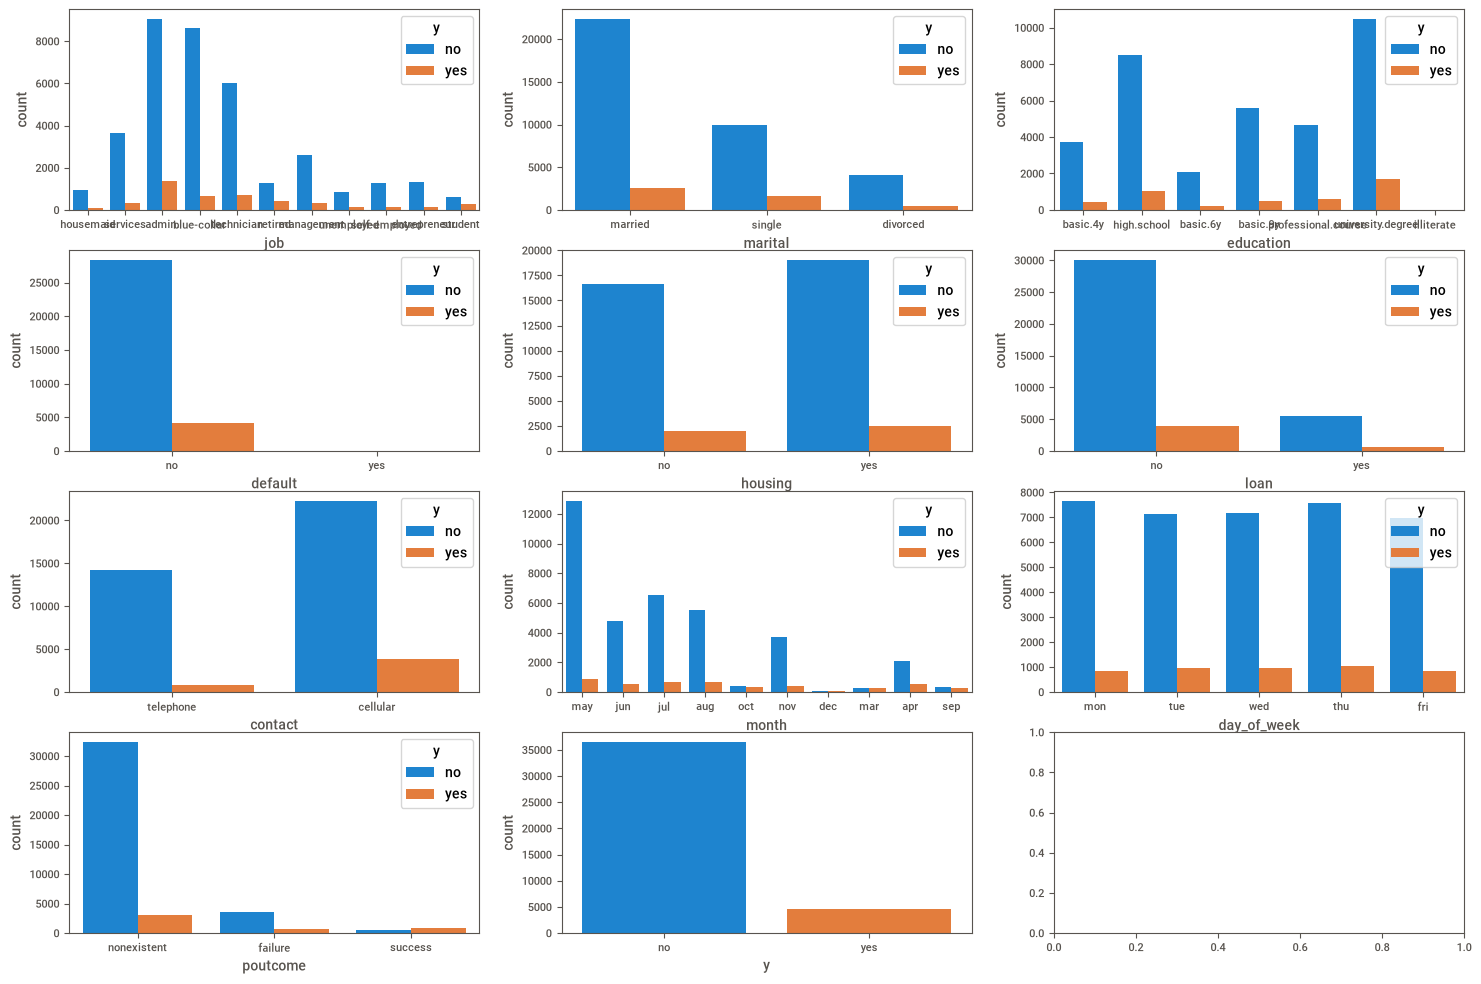

In [25]:
categorical = ['job', 'marital', 'education', 'default', 'housing', 'loan',
               'contact', 'month','day_of_week', 'poutcome','y']
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(18, 12))
for col, ax in zip(categorical[0:], axs.ravel()):
    sns.countplot(x=col, data=data, ax=ax,hue=data.y)

In [26]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             40858 non-null  str    
 2   marital         41108 non-null  str    
 3   education       39457 non-null  str    
 4   default         32591 non-null  str    
 5   housing         40198 non-null  str    
 6   loan            40198 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null  float64
 1

# Data Preprocessing

In [27]:
data.isnull().sum()

age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp_var_rate         0
cons_price_idx       0
cons_conf_idx        0
euribor3m            0
nr_employed          0
y                    0
dtype: int64

In [28]:
## Imputing the missing values
## job, education,contact,poutcome has missing values and as they are object type data,
##so compute the missing values wee need to use mode

In [29]:
## Getting the rows where values got missed

In [30]:
data.loc[data['job'].isnull()==True]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
29,55,NaN,married,university.degree,NaN,NaN,NaN,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
35,55,NaN,married,basic.4y,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
73,57,NaN,married,NaN,NaN,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
91,57,NaN,married,NaN,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
144,38,NaN,divorced,high.school,NaN,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40370,59,NaN,married,NaN,no,no,no,cellular,aug,wed,...,1,6,1,success,-1.7,94.027,-38.3,0.900,4991.6,yes
40428,64,NaN,married,NaN,no,yes,no,telephone,aug,fri,...,4,999,0,nonexistent,-1.7,94.027,-38.3,0.905,4991.6,yes
40656,67,NaN,divorced,NaN,NaN,yes,no,cellular,sep,wed,...,2,6,2,success,-1.1,94.199,-37.5,0.880,4963.6,yes
41005,63,NaN,married,professional.course,no,no,no,cellular,oct,thu,...,1,6,1,success,-1.1,94.601,-49.5,1.025,4963.6,no


In [31]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             40858 non-null  str    
 2   marital         41108 non-null  str    
 3   education       39457 non-null  str    
 4   default         32591 non-null  str    
 5   housing         40198 non-null  str    
 6   loan            40198 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null  float64
 1

In [32]:
## Impuation using inbuild method fillna.

In [33]:
data['job'] = data['job'].fillna(data['job'].mode()[0])

data['marital'] = data['marital'].fillna(data['marital'].mode()[0])

data['education'] = data['education'].fillna(data['education'].mode()[0])

data['default'] = data['default'].fillna(data['default'].mode()[0])

data['housing'] = data['housing'].fillna(data['housing'].mode()[0])

data['loan'] = data['loan'].fillna(data['loan'].mode()[0])

In [34]:
data.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp_var_rate      0
cons_price_idx    0
cons_conf_idx     0
euribor3m         0
nr_employed       0
y                 0
dtype: int64

In [35]:
## There are categorical data need to convert them into numerical

In [36]:
data.job.value_counts()

job
admin.           10752
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
Name: count, dtype: int64

In [37]:
data.job=data.job.map({'admin.':1,'blue-collar':2,'technician':3,'services':4,'management':5,'retired':6,
                       'entrepreneur':7,'self-employed':8,'housemaid':9,'unemployed':10,'student':11 })

In [38]:
data.job.value_counts()

job
1     10752
2      9254
3      6743
4      3969
5      2924
6      1720
7      1456
8      1421
9      1060
10     1014
11      875
Name: count, dtype: int64

In [39]:
data.marital.value_counts(())

marital
married     25008
single      11568
divorced     4612
Name: count, dtype: int64

In [40]:
data.marital=data.marital.map({'married':1,'single':2,'divorced':3})

In [41]:
data.education.value_counts()

education
university.degree      13899
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
illiterate                18
Name: count, dtype: int64

In [42]:
data.education=data.education.map({'university.degree':1,'high.school':2,'basic.9y':3,'professional.course':4,
                                   'basic.4y':5,'basic.6y':6,'illiterate':7})

In [43]:
data.default.value_counts()

default
no     41185
yes        3
Name: count, dtype: int64

In [44]:
data.default=data.default.map({'no':0,'yes':1})

In [45]:
data.housing.value_counts()

housing
yes    22566
no     18622
Name: count, dtype: int64

In [46]:
data.housing=data.housing.map({'no':0,'yes':1})

In [47]:
data.loan.value_counts()

loan
no     34940
yes     6248
Name: count, dtype: int64

In [48]:
data.loan=data.loan.map({'no':0,'yes':1})

In [49]:
data.month.value_counts()

month
may    13769
jul     7174
aug     6178
jun     5318
nov     4101
apr     2632
oct      718
sep      570
mar      546
dec      182
Name: count, dtype: int64

In [50]:
data.month=data.month.map({'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                           'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12})

In [51]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  int64  
 2   marital         41188 non-null  int64  
 3   education       41188 non-null  int64  
 4   default         41188 non-null  int64  
 5   housing         41188 non-null  int64  
 6   loan            41188 non-null  int64  
 7   contact         41188 non-null  str    
 8   month           41188 non-null  int64  
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null  float64
 1

In [52]:
data.contact.value_counts()

contact
cellular     26144
telephone    15044
Name: count, dtype: int64

In [53]:
# Converting the numerical equivalent

In [54]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
data['contact']=le.fit_transform(data['contact'])

In [55]:
data.day_of_week.value_counts()

day_of_week
thu    8623
mon    8514
wed    8134
tue    8090
fri    7827
Name: count, dtype: int64

In [56]:
data.day_of_week=data.day_of_week.map({'mon':1,'tue':2,'wed':3,'thu':4,'fri':5})

In [57]:
data.poutcome.value_counts()

poutcome
nonexistent    35563
failure         4252
success         1373
Name: count, dtype: int64

In [58]:
data.poutcome=data.poutcome.map({'nonexistent':0,'failure':1,'success':2})

In [59]:
data.y.value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [60]:
data.y=data.y.map({'no':0,'yes':1})

In [61]:
## Lets check outliers in any
## chekcing the outliers

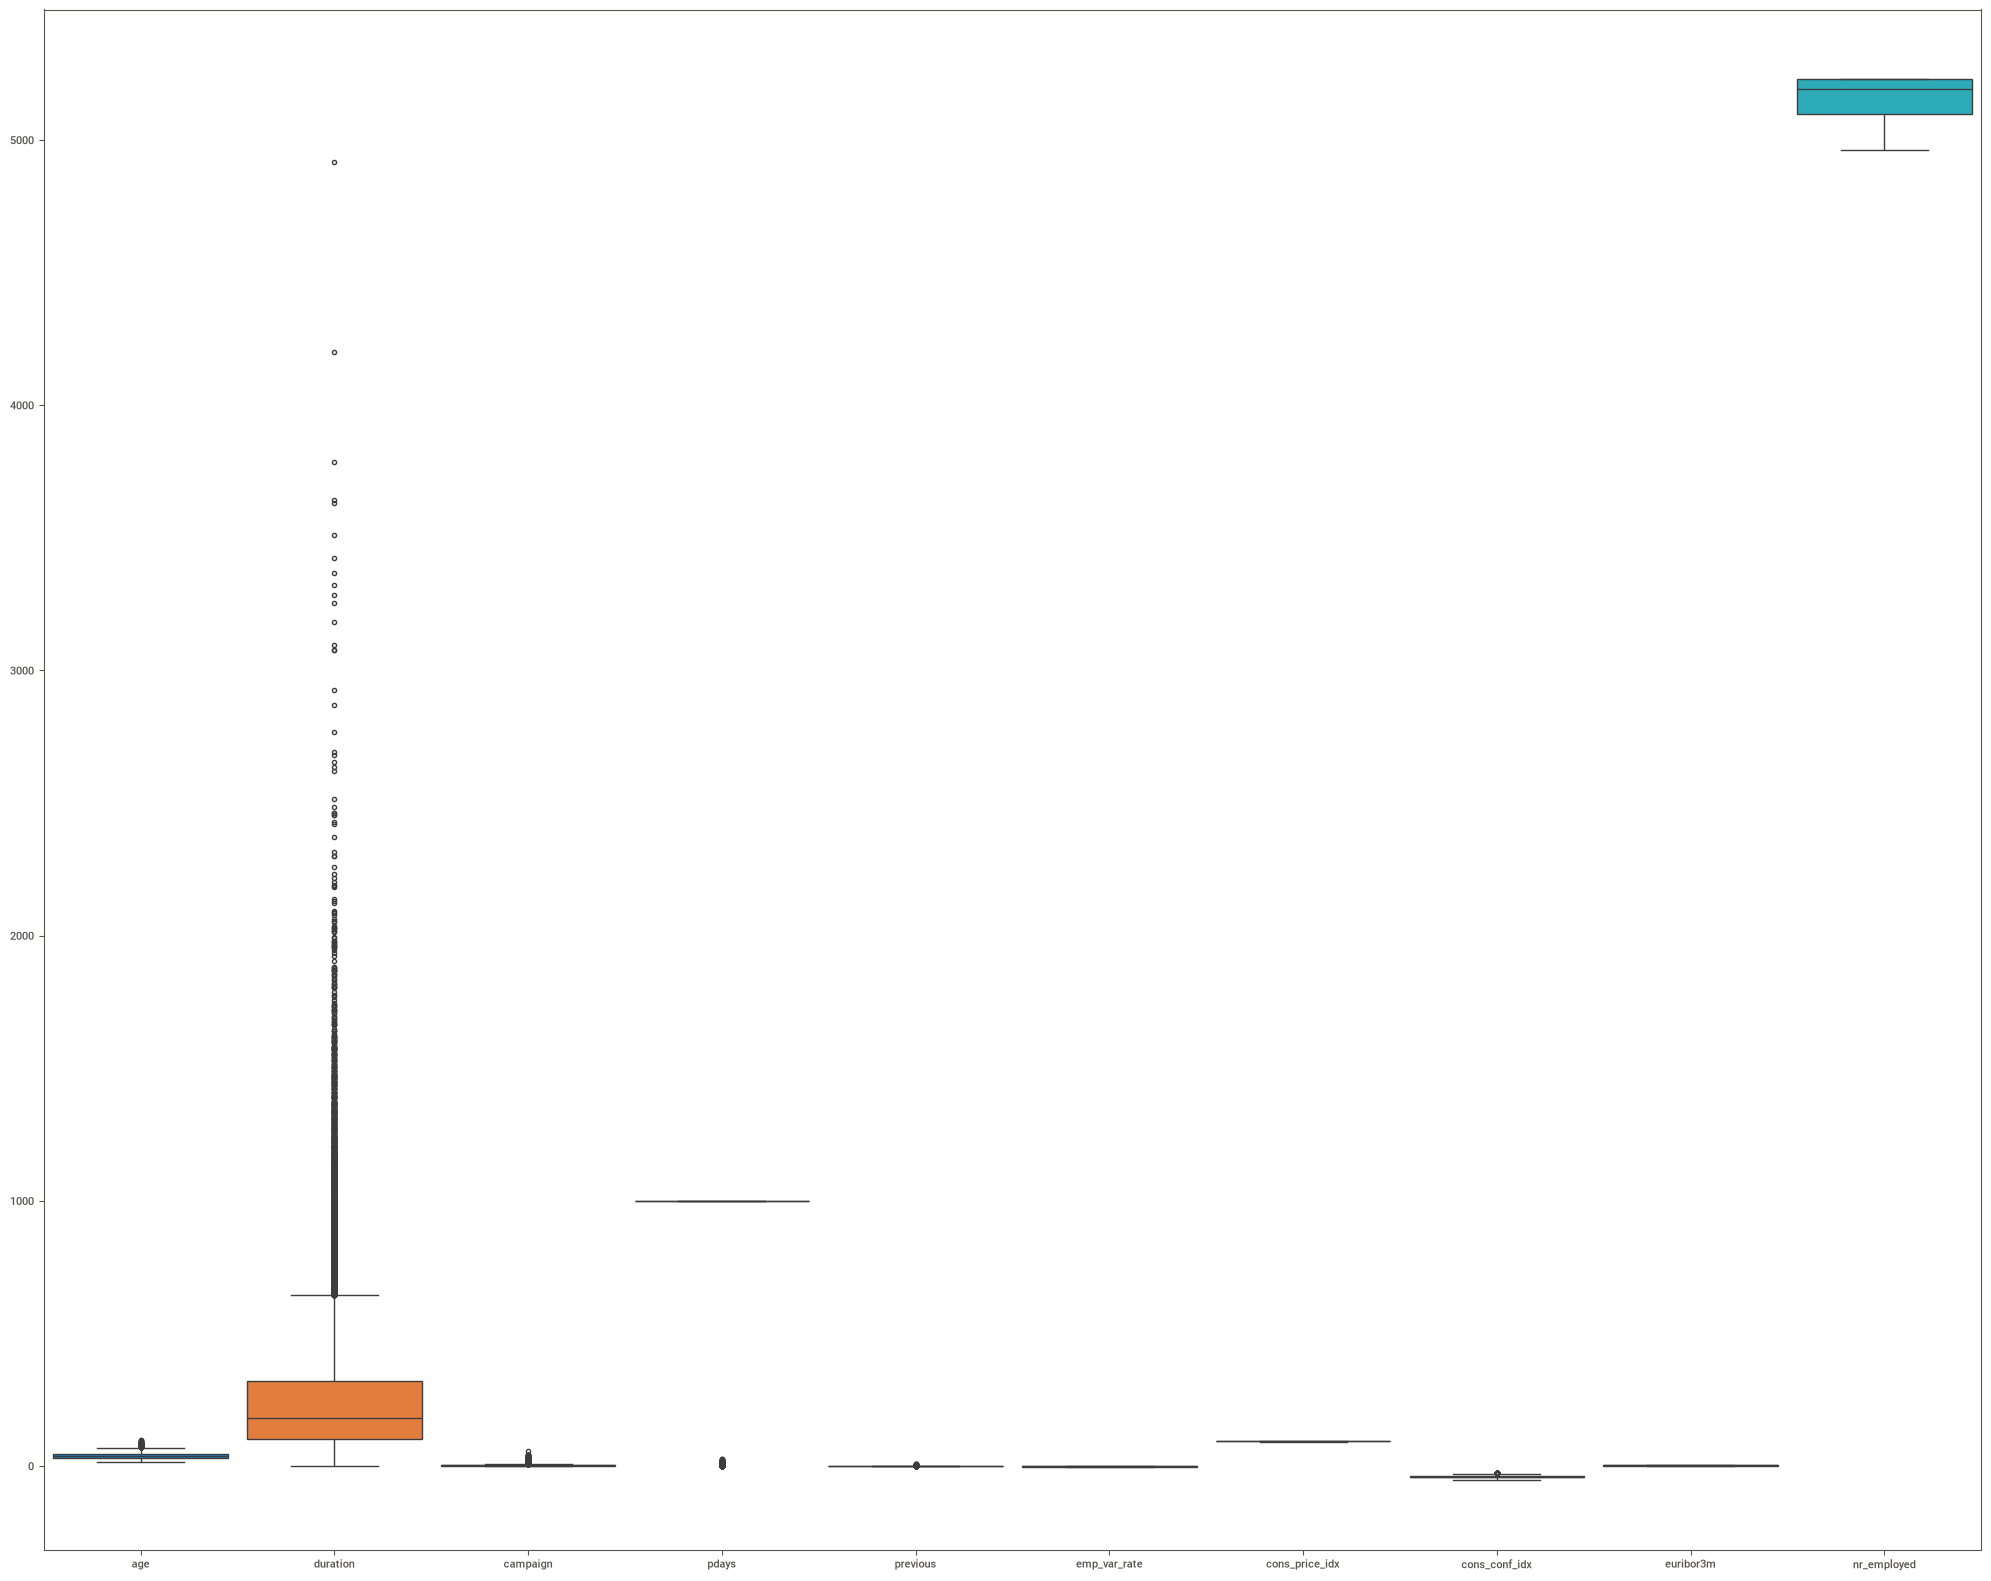

In [62]:
fig, ax = plt.subplots(figsize=(25,20))
sns.boxplot(data=data1, width= 0.9,ax=ax,  fliersize=3)
plt.show()

<Axes: ylabel='pdays'>

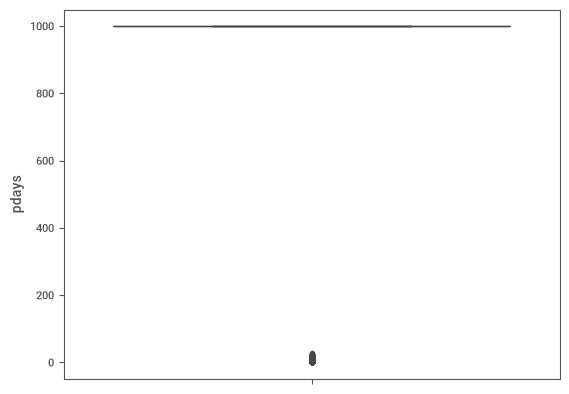

In [63]:
sns.boxplot(data.pdays)

# Feature Selection

In [64]:
## there is highly correlative columns like 
##emp_var_rate,euribor3m are highly correlated to each other,so we will drop one of them
##emp_var_rate,nr_employed are highly correlated to each other, so we will drop one of them
##euribor3m,nr_employed are highly correlated to each other, so we will drop one of them

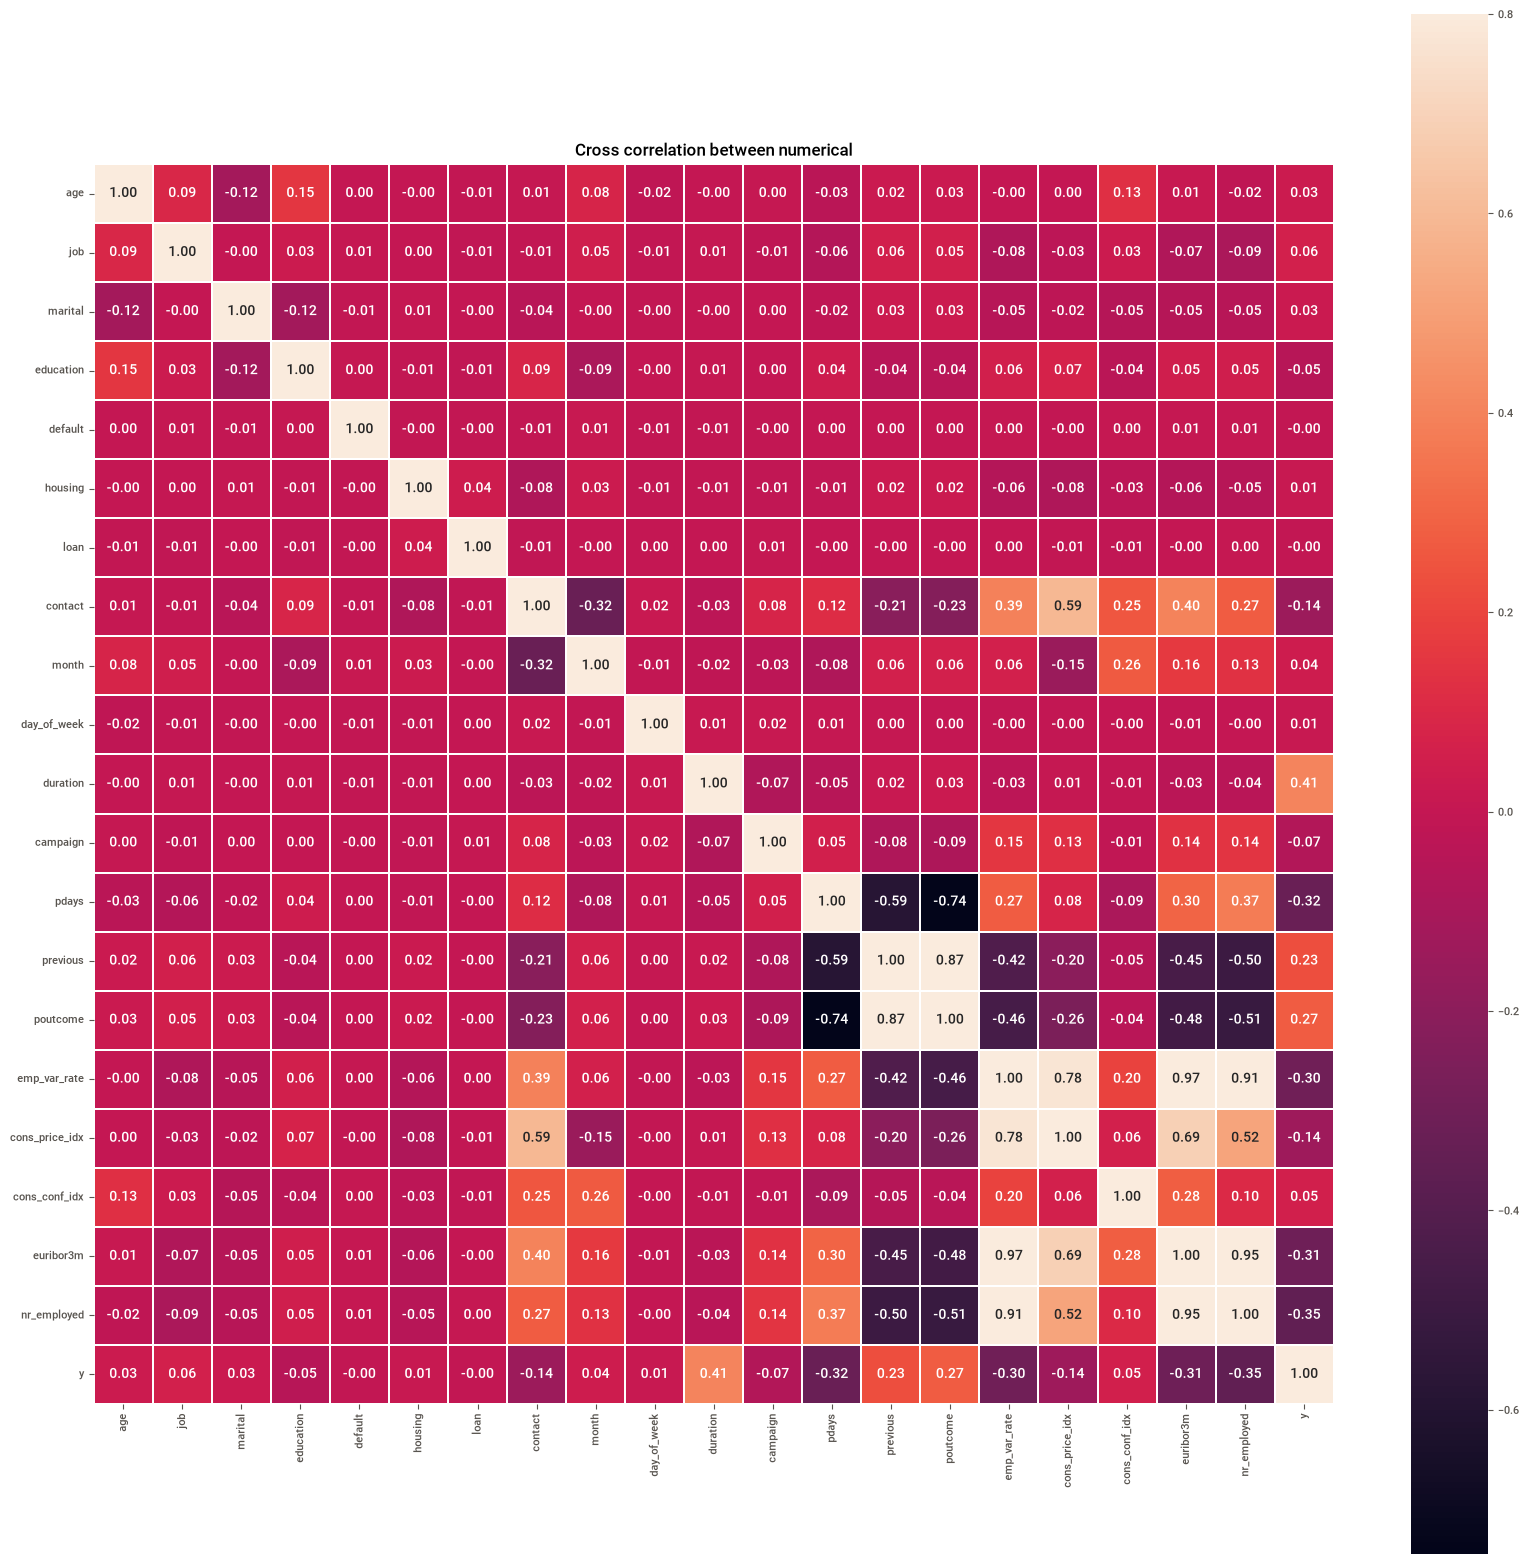

In [65]:
plt.figure(figsize=(20, 20))
ax = sns.heatmap(data.corr(), vmax=.8, square=True, fmt='.2f', annot=True, linecolor='white', linewidths=0.01)
plt.title('Cross correlation between numerical')
plt.show()

In [66]:
data2 = data.drop(['emp_var_rate','nr_employed'],axis=1)
data2.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m,y
0,56,9,1,5,0,0,0,1,5,1,261,1,999,0,0,93.994,-36.4,4.857,0
1,57,4,1,2,0,0,0,1,5,1,149,1,999,0,0,93.994,-36.4,4.857,0
2,37,4,1,2,0,1,0,1,5,1,226,1,999,0,0,93.994,-36.4,4.857,0
3,40,1,1,6,0,0,0,1,5,1,151,1,999,0,0,93.994,-36.4,4.857,0
4,56,4,1,2,0,0,1,1,5,1,307,1,999,0,0,93.994,-36.4,4.857,0


In [67]:
## checking the duplicate rows

In [68]:
data2.duplicated().sum()

14

In [69]:
## droping the duplicate rows

In [70]:
data2.drop_duplicates(inplace=True)

In [71]:
## checking the constant features

In [72]:
## the standard deviation of all features are not 0 ,so the there are constant features in the dataset.

In [73]:
data2.describe()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m,y
count,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000,41174.000000
mean,40.023583,3.427649,1.504833,2.592874,0.000073,0.547919,0.151746,0.365279,6.607738,2.979623,258.323627,2.567956,962.463035,0.173022,0.169962,93.575713,-40.503070,3.621231,0.112668
std,10.420578,2.600824,0.688451,1.567050,0.008536,0.497705,0.358779,0.481514,2.041036,1.411531,259.309058,2.770364,186.941469,0.494975,0.455820,0.578849,4.627877,1.734456,0.316191
min,17.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,92.201000,-50.800000,0.634000,0.000000
25%,32.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2.000000,102.000000,1.000000,999.000000,0.000000,0.000000,93.075000,-42.700000,1.344000,0.000000
50%,38.000000,3.000000,1.000000,2.000000,0.000000,1.000000,0.000000,0.000000,6.000000,3.000000,180.000000,2.000000,999.000000,0.000000,0.000000,93.749000,-41.800000,4.857000,0.000000
75%,47.000000,5.000000,2.000000,4.000000,0.000000,1.000000,0.000000,1.000000,8.000000,4.000000,319.000000,3.000000,999.000000,0.000000,0.000000,93.994000,-36.400000,4.961000,0.000000
max,98.000000,11.000000,3.000000,7.000000,1.000000,1.000000,1.000000,1.000000,12.000000,5.000000,4918.000000,56.000000,999.000000,7.000000,2.000000,94.767000,-26.900000,5.045000,1.000000


# Model Creation

In [74]:
## Defining X and y and creating dependent and independent variables

In [75]:
X = data2.drop(columns = ['y']) ## independent variable
y = data2['y'] ## Dependent or target variable"

In [76]:
X

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,cons_price_idx,cons_conf_idx,euribor3m
0,56,9,1,5,0,0,0,1,5,1,261,1,999,0,0,93.994,-36.4,4.857
1,57,4,1,2,0,0,0,1,5,1,149,1,999,0,0,93.994,-36.4,4.857
2,37,4,1,2,0,1,0,1,5,1,226,1,999,0,0,93.994,-36.4,4.857
3,40,1,1,6,0,0,0,1,5,1,151,1,999,0,0,93.994,-36.4,4.857
4,56,4,1,2,0,0,1,1,5,1,307,1,999,0,0,93.994,-36.4,4.857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,6,1,4,0,1,0,0,11,5,334,1,999,0,0,94.767,-50.8,1.028
41184,46,2,1,4,0,0,0,0,11,5,383,1,999,0,0,94.767,-50.8,1.028
41185,56,6,1,1,0,1,0,0,11,5,189,2,999,0,0,94.767,-50.8,1.028
41186,44,3,1,4,0,0,0,0,11,5,442,1,999,0,0,94.767,-50.8,1.028


In [77]:
y

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: y, Length: 41174, dtype: int64

In [78]:
## scaling the data as all features seems to be near to normal distribution

In [79]:
from sklearn.preprocessing import StandardScaler 
scalar = StandardScaler()## objet creation
X_scaled = scalar.fit_transform(X)

In [80]:
## Balacing the data

In [81]:
from collections import Counter
from imblearn.over_sampling import SMOTE
sm=SMOTE()
print(Counter(y))
X_sm,y_sm=sm.fit_resample(X_scaled,y)
print(Counter(y_sm))

Counter({0: 36535, 1: 4639})
Counter({0: 36535, 1: 36535})


In [82]:
## creating training and testing data

In [83]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(X_sm,y_sm, test_size= 0.20,random_state = 355)

# Logistic Regression Model

In [84]:
# Model1 creation

In [85]:
from sklearn.linear_model import LogisticRegression
model1 = LogisticRegression()## object Creation

model1.fit(x_train,y_train)## fitting the model with training data

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [86]:
y_pred = model1.predict(x_test)

In [87]:
pd.crosstab(y_test,y_pred)

col_0,0,1
y,,
0,6249,1083
1,980,6302


In [88]:
## calculating accuracy

In [89]:
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
accuracy = accuracy_score(y_test,y_pred)
accuracy

0.8588339947995073

In [90]:
# Precison

In [91]:
Precision = precision_score(y_test,y_pred)
Precision

0.8533513879485444

In [92]:
# Recall

In [93]:
Recall = recall_score(y_test,y_pred)
Recall

0.8654215874759681

In [94]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.85      0.86      7332
           1       0.85      0.87      0.86      7282

    accuracy                           0.86     14614
   macro avg       0.86      0.86      0.86     14614
weighted avg       0.86      0.86      0.86     14614



# KNN Model

In [95]:
# creating 2nd model

In [96]:
from sklearn.neighbors import KNeighborsClassifier
model2 = KNeighborsClassifier()
model2.fit(x_train,y_train)
y_hat1=model2.predict(x_test)

In [97]:
## for logestic regression model

In [98]:
from sklearn.metrics import roc_auc_score
score=roc_auc_score(y_test,y_pred)
score

0.8588564565857746

In [99]:
## for KNN model

In [100]:
from sklearn.metrics import roc_auc_score
score=roc_auc_score(y_test,y_hat1)
score

0.9262628535142515

In [101]:
#std of < 0.05 is good.

In [102]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model1,X,y,cv=5,scoring='roc_auc')
print(scores)
print("Cross validation Score:",scores.mean())
print("Std :",scores.std())

C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

[0.94406934 0.94114318 0.96237356 0.79671521 0.86326215]
Cross validation Score: 0.9015126867165174
Std : 0.06250008624792387


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [103]:
#std of < 0.05 is good. 

In [104]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model2,X,y,cv=5,scoring='roc_auc')
print(scores)
print("Cross validation Score:",scores.mean())
print("Std :",scores.std())
#std of < 0.05 is good. 

[0.78694681 0.70727032 0.76160429 0.66790436 0.75127838]
Cross validation Score: 0.7350008344370497
Std : 0.042289491818088026


In [105]:
error_rate=[]
for i in range(1,11):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    pred_i = knn.predict(x_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error rate')

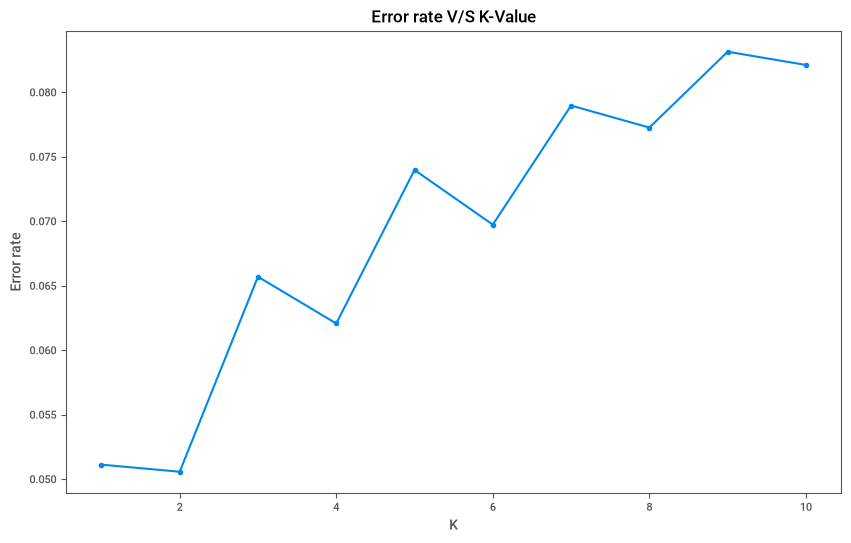

In [106]:
plt.figure(figsize=(10,6))
plt.plot(range(1,11),error_rate,marker='o')
plt.title('Error rate V/S K-Value')
plt.xlabel('K')
plt.ylabel('Error rate')

In [107]:
knn=KNeighborsClassifier(n_neighbors=2)
knn.fit(x_train,y_train)
y_pred=knn.predict(x_test)

In [108]:
acc=accuracy_score(y_test,y_pred)
acc

0.9494320514575065

In [109]:
recall=recall_score(y_test,y_pred)
recall

0.9815984619609998

In [110]:
f1=f1_score(y_test,y_pred)
f1

0.9508480212836714

In [111]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.92      0.95      7332
           1       0.92      0.98      0.95      7282

    accuracy                           0.95     14614
   macro avg       0.95      0.95      0.95     14614
weighted avg       0.95      0.95      0.95     14614



# Bagging Classifier Model

In [112]:
# using Bagging

In [113]:
import sklearn
from sklearn.ensemble import BaggingClassifier

print("scikit-learn:", sklearn.__version__)

try:
    model_bagg1 = BaggingClassifier(estimator=model2, n_estimators=10)        # sklearn >= 1.2
except TypeError:
    model_bagg1 = BaggingClassifier(base_estimator=model2, n_estimators=10)   # sklearn < 1.2

model_bagg1.fit(x_train, y_train)
y_hat_bagg = model_bagg1.predict(x_test)

scikit-learn: 1.9.0


In [114]:
f1_score(y_test,y_hat_bagg,average='weighted') ## f1  score calculation

0.927514412907391

In [115]:
#std of < 0.05 is good.

In [116]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model_bagg1,X,y,cv=5,scoring='roc_auc')
print(scores)
print("Cross validation Score:",scores.mean())
print("Std :",scores.std())

[0.84947011 0.72573617 0.80932594 0.68500689 0.76259439]
Cross validation Score: 0.7664267016405621
Std : 0.05837147209365534


# Random Forest Model

In [117]:
# model4 creation

In [118]:
from sklearn.ensemble import RandomForestClassifier

model4 = RandomForestClassifier(n_estimators=100)
model4.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [119]:
y_predict=model4.predict(x_test)
y_predict

array([0, 0, 1, ..., 1, 1, 1], dtype=int64)

In [120]:
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.98      0.93      0.95      7332
           1       0.93      0.98      0.96      7282

    accuracy                           0.96     14614
   macro avg       0.96      0.96      0.96     14614
weighted avg       0.96      0.96      0.96     14614



In [121]:
f_Score=f1_score(y_test,y_predict)
f_Score

0.9558971605021145

In [122]:
#std of < 0.05 is good.

In [123]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model4,X,y,cv=5,scoring='roc_auc')
print(scores)
print("Cross validation Score:",scores.mean())
print("Std :",scores.std())

[0.26517904 0.232652   0.21006029 0.08974596 0.17897794]
Cross validation Score: 0.19532304556216495
Std : 0.059840089255687186


# SVM Model

In [124]:
from sklearn.svm import SVC
svc=SVC()
svc.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [125]:
y_pred=svc.predict(x_test)

In [126]:
acc=accuracy_score(y_test,y_pred)
acc

0.8997536608731354

In [127]:
from sklearn.metrics import accuracy_score,auc, confusion_matrix,precision_score,recall_score,f1_score,classification_report
print(classification_report(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.95      0.84      0.89      7332
           1       0.86      0.95      0.90      7282

    accuracy                           0.90     14614
   macro avg       0.90      0.90      0.90     14614
weighted avg       0.90      0.90      0.90     14614



In [128]:
f_Score=f1_score(y_test,y_pred)
f_Score

0.9047030508033566

# Decision Tree Model

In [129]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
y_pred=dt.predict(x_test)

In [130]:
acc=accuracy_score(y_test,y_pred)
acc

0.9247297112358013

In [131]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.92      0.92      7332
           1       0.92      0.93      0.92      7282

    accuracy                           0.92     14614
   macro avg       0.92      0.92      0.92     14614
weighted avg       0.92      0.92      0.92     14614



In [132]:
f_Score=f1_score(y_test,y_pred)
f_Score

0.9249658935879945

# Naive Bayes Model

In [133]:
from sklearn.naive_bayes import BernoulliNB
nb=BernoulliNB(alpha=0.01)
nb.fit(x_train,y_train)
y_pred=nb.predict(x_test)

In [134]:
acc=accuracy_score(y_test,y_pred)
acc

0.7450390036950869

In [135]:
recall=recall_score(y_test,y_pred)
recall

0.6827794561933535

In [136]:
f1=f1_score(y_test,y_pred)
f1

0.7274323335771763

In [137]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.81      0.76      7332
           1       0.78      0.68      0.73      7282

    accuracy                           0.75     14614
   macro avg       0.75      0.74      0.74     14614
weighted avg       0.75      0.75      0.74     14614



# GradientBoostingClassifier Model

In [138]:
# importing the 5th model library

In [139]:
from sklearn.ensemble import GradientBoostingClassifier
gbm=GradientBoostingClassifier() ## object creation
gbm.fit(x_train,y_train) ## fitting the data
y_gbm=gbm.predict(x_test)

In [140]:
acc=accuracy_score(y_test,y_gbm)
acc

0.9328041603941426

In [141]:
recall=recall_score(y_test,y_pred)
recall

0.6827794561933535

In [142]:
# Precison

In [143]:
Precision = precision_score(y_test,y_pred)
Precision

0.778334376956794

In [144]:
f1=f1_score(y_test,y_pred)
f1

0.7274323335771763

In [145]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.72      0.81      0.76      7332
           1       0.78      0.68      0.73      7282

    accuracy                           0.75     14614
   macro avg       0.75      0.74      0.74     14614
weighted avg       0.75      0.75      0.74     14614



# XGB Model

In [146]:
from xgboost import XGBClassifier

In [147]:
xgb=XGBClassifier()
xgb.fit(x_train,y_train)
y_pred=xgb.predict(x_test)

In [148]:
acc=accuracy_score(y_test,y_pred)
acc

0.9534692760366772

In [149]:
recall=recall_score(y_test,y_pred)
recall

0.9564680032957978

In [150]:
f1=f1_score(y_test,y_pred)
f1

0.9534565366187543

In [151]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.96      0.95      0.95      7332
           1       0.95      0.96      0.95      7282

    accuracy                           0.95     14614
   macro avg       0.95      0.95      0.95     14614
weighted avg       0.95      0.95      0.95     14614



# Hyperparameter Tuning for the Best Model

In [152]:
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start=200, stop=1000, num=10)]
max_features = ['auto', 'sqrt']
max_depth = [int(x) for x in np.linspace(10, 40, num=9)]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4]
bootstrap = [True, False]

random_grid = {'n_estimators': n_estimators, 'max_features': max_features,
               'max_depth': max_depth, 'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf, 'bootstrap': bootstrap}

rf_clf1 = RandomForestClassifier(random_state=42)

rf_cv = RandomizedSearchCV(estimator=model4, scoring='f1',param_distributions=random_grid, n_iter=100, cv=3, 
                               verbose=2, random_state=42, n_jobs=-1)

rf_cv.fit(x_train, y_train)
rf_best_params = rf_cv.best_params_
print(f"Best paramters: {rf_best_params})")

Fitting 3 folds for each of 100 candidates, totalling 300 fits


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
126 fits failed out of a total of 300.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py", line 1393, in wrapper
    estimator._validate_params()
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.

Best paramters: {'n_estimators': 466, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 36, 'bootstrap': False})
